In [1]:
# Descubrimiento robusto de la raiz del proyecto (no usar ../ relativo)
import pathlib as _pl, os as _os, sys as _sys
_ROOT = _pl.Path().resolve()
while not (_ROOT / "pyproject.toml").exists() and _ROOT != _ROOT.parent:
    _ROOT = _ROOT.parent
_os.chdir(_ROOT)
if str(_ROOT) not in _sys.path:
    _sys.path.insert(0, str(_ROOT))
if str(_ROOT / "src") not in _sys.path:
    _sys.path.insert(0, str(_ROOT / "src"))
print("cwd:", _os.getcwd())


cwd: C:\Users\mikel\Desktop\Pruebas\nasa


# 02 — 5 modelos clásicos + GridSearch (SAA 6/8)

Ridge fila (baseline clasico), KNN, RF, XGB, SVR sobre filas imputadas MAR con Pipeline(pre, reg) compartido y GroupKFold(3, groups=unit). SVR sobre submuestra 5k por coste O(n2). El híbrido congelado se cita como extra no visto en clase (SAA 6 -> 10). Métrica negocio: RMSE + MAE; test 1 vez (uds 11/14/15).

**Cómo leerlo**: Objetivo (¿los 5 aguantan el MAR+ffill?) → Qué hago (un Pipeline(pre, reg) por modelo, GroupKFold por motor) → Qué veo (tabla + real-vs-predicho + por motor) → Cierre (elegido por RMSE-negocio, el híbrido como extra no visto en clase).

> **No confundir Ridge:** este Ridge fila predice RUL desde 1 fila (baseline). No es el Ridge fisico de 01 (limpia sensores) ni el ridge_meta de 05 (mezcla dos predicciones del bundle C).


In [2]:
import os, sys; 
import pandas as pd
comp = pd.read_csv('resultados/comparativa.csv')
print(comp[['modelo','rmse_train','rmse_val','mae_val','r2_val','rmse_test','tiempo_s']].to_string(index=False))
mejor = comp.sort_values('rmse_val').iloc[0]
print('Modelo elegido (menor RMSE validacion out-of-fold):', mejor['modelo'], '| RMSE val', mejor['rmse_val'])
print('Test: UNA sola lectura y solo del elegido ->', mejor['modelo'], mejor['rmse_test'])
print('RMSE = coste de fallos gordos; MAE = error medio; R2 = varianza explicada.')


   modelo  rmse_train  rmse_val  mae_val  r2_val  rmse_test  tiempo_s
      knn      6.9840    9.4092   8.1856  0.8181        NaN       9.1
regresion      8.2004    8.2762   7.6611  0.8502        NaN       3.5
       rf      7.1572    9.0704   8.1534  0.8270        NaN      79.6
      svm      7.5251    8.2927   7.5299  0.8565        NaN       2.7
      xgb      7.1887    8.2173   7.4688  0.8543     11.034       7.2
Modelo elegido (menor RMSE validacion out-of-fold): xgb | RMSE val 8.2173
Test: UNA sola lectura y solo del elegido -> xgb 11.034
RMSE = coste de fallos gordos; MAE = error medio; R2 = varianza explicada.


> Procedencia: `resultados/comparativa.csv` ← `src/clase/train_clasicos.py` (seed 42, GroupKFold(3, groups=unit)). Regenerable con: `python src/clase/train_clasicos.py`. Si el CSV cambia sin re-ejecutar su fuente, la celda ancla lo detecta.

In [3]:
# ENTRENO OFICIAL EN VIVO (mismo loop que `src/clase/train_clasicos.py`,
# orquestado aqui sin escribir nada: ni CSV ni joblib. Todo queda en memoria).
import sys; 
import time
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupKFold, GridSearchCV
from src.utils import make_pipeline
from src.clase.train_clasicos import (
    ESPEC, CV, SCORING, RANDOM_STATE, SVR_MUESTRA, ORDEN_SIMPLE,
    _metricas_train, _metricas_val)
_Xtr = pd.read_parquet('data/processed/X_train.parquet')
_ytr = pd.read_parquet('data/processed/y_train.parquet').values.ravel().astype(float)
_gtr = _Xtr['unit'].to_numpy()
_filas = []
for _nombre, (_reg, _grid) in ESPEC.items():
    _pipe = make_pipeline(_reg)
    _t0 = time.time()
    if _nombre == 'svm':
        _rng = np.random.default_rng(RANDOM_STATE)
        _idx = _rng.choice(len(_Xtr), size=min(SVR_MUESTRA, len(_Xtr)), replace=False)
        _Xs, _ys, _gs = _Xtr.iloc[_idx], _ytr[_idx], _gtr[_idx]
        _gsc = GridSearchCV(_pipe, _grid, cv=GroupKFold(3), scoring=SCORING, refit='rmse', n_jobs=-1)
        _gsc.fit(_Xs, _ys, groups=_gs)
    else:
        _gsc = GridSearchCV(_pipe, _grid, cv=CV, scoring=SCORING, refit='rmse', n_jobs=-1)
        _gsc.fit(_Xtr, _ytr, groups=_gtr)
    _secs = time.time() - _t0
    _best = _gsc.best_estimator_
    _m = {**_metricas_train(_ytr, _best.predict(_Xtr)), **_metricas_val(_gsc)}
    _filas.append({'modelo': _nombre, 'mejores_params': str(_gsc.best_params_),
                   'tiempo_s': round(_secs, 1),
                   **{k: round(v, 4) for k, v in _m.items()}})
    print(f'{_nombre}: RMSE val {_m["rmse_val"]:.4f} | {_gsc.best_params_} | {_secs:.0f}s')
_viva = pd.DataFrame(_filas).sort_values('modelo')
_csv = pd.read_csv('resultados/comparativa.csv').sort_values('modelo')
_d = float(np.abs(_viva['rmse_val'].values - _csv['rmse_val'].values).max())
print(f'diferencia maxima en rmse_val vs comparativa.csv: {_d:.4f}')
assert _d < 0.01, 'el re-entreno no reproduce el CSV oficial'
_win_viva = _viva.assign(_o=_viva['modelo'].map(ORDEN_SIMPLE)).sort_values(['rmse_val', '_o']).iloc[0]['modelo']
_win_csv = _csv.assign(_o=_csv['modelo'].map(ORDEN_SIMPLE)).sort_values(['rmse_val', '_o']).iloc[0]['modelo']
assert _win_viva == _win_csv == 'xgb', 'el elegido en vivo y en CSV difieren'
print(f'ELEGIDO (menor RMSE val): {_win_csv} | test(1 lectura) ' + str(_csv.loc[_csv["modelo"] == _win_csv, 'rmse_test'].iloc[0]))
print('TABLA OK: el notebook calcula lo mismo que el CSV archivado.')


regresion: RMSE val 8.2762 | {'reg__alpha': 10.0} | 4s
knn: RMSE val 9.4092 | {'reg__n_neighbors': 31} | 7s
rf: RMSE val 9.0704 | {'reg__max_depth': 8} | 50s
xgb: RMSE val 8.2173 | {'reg__max_depth': 4} | 5s
svm: RMSE val 8.2927 | {'reg__C': 10.0, 'reg__epsilon': 1.0} | 2s
diferencia maxima en rmse_val vs comparativa.csv: 0.0000
ELEGIDO (menor RMSE val): xgb | test(1 lectura) 11.034
TABLA OK: el notebook calcula lo mismo que el CSV archivado.


## Cómo leer esta tabla (baseline primero, regla de empate)

- El baseline es `regresion` = Ridge fila (baseline clasico, val 8.28): cualquier modelo útil tiene que ganarle. El elegido es `xgb` (val 8.22) por delante de `svm` (8.29): la elección se fija en validación out-of-fold, no en test.
- **Test una sola vez:** solo XGB trae test (11.03). El test confirma, no reelige: con protocolo honesto el elegido es XGB aunque SVM marcara 9.06 en la era test-selección.
- **Regla de empate (por escrito):** se resta el RMSE-val del 1.º y del 2.º; si la diferencia es menor que el spread entre folds, gana el más simple. Aquí XGB (8.22) le saca 0.06 al Ridge fila (8.28): no hay empate que desempatar.
- El híbrido C (fila oficial del manifiesto, grano ventana; no compite en esta liga de fila): RMSE 4.338 / MAE 3.227 / R2 0.9461 / NASA Score 2336.2. Se cita por contexto, no es resultado de este cuaderno.
- **Qué vemos:** el orden se mantiene con el CSV archivado al céntimo — el re-entreno es determinista (seeds fijas, GroupKFold por motor).

**Por qué se llama regresión en el CSV:** `comparativa.csv` guarda el Ridge como `regresion` (nombre historico). Es el mismo Ridge por fila de arriba, no el residualizer de 01 ni el meta de 05.


In [4]:
# CV DEL ELEGIDO (GroupKFold 3 por motor, su regimen de entreno: train completo,
# semilla 42 identica a la oficial). Media +- std del RMSE, no un numero suelto.
import sys; 
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupKFold, cross_val_score
from xgboost import XGBRegressor
from src.utils import make_pipeline
_X = pd.read_parquet('data/processed/X_train.parquet')
_y = pd.read_parquet('data/processed/y_train.parquet').values.ravel()
_s = cross_val_score(make_pipeline(XGBRegressor(
    n_estimators=300, max_depth=4, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8, n_jobs=-1,
    random_state=42, verbosity=0)),
    _X, _y, groups=_X['unit'].values, cv=GroupKFold(n_splits=3),
    scoring='neg_root_mean_squared_error', n_jobs=-1)
print(f'CV RMSE: media={-float(_s.mean()):.4f} std={float(_s.std()):.4f} (3 folds, train completo)')
print('Test oficial (1 lectura, solo elegido): RMSE=11.034 — el test no reelige, solo confirma.')


CV RMSE: media=8.2173 std=3.0720 (3 folds, train completo)
Test oficial (1 lectura, solo elegido): RMSE=11.034 — el test no reelige, solo confirma.


> Nota de coste (por que el SVR oficial va en submuestra 5k): el SVR con kernel RBF
> es O(n²) en memoria/tiempo; en 52k filas es inviable en un portatil. El oficial se
> entrena en 5000 filas estratificadas por motor (`src/clase/train_clasicos.py`).
> El resto de modelos ven el train completo.

## Real vs predicho (mejor clásico, test)

**Como leer (antes de la figura, clasico).** Cada punto es una fila de test: eje X la RUL real, eje Y la predicha. Pegado a la diagonal roja = acierta; disperso = no sabe. Son 2.000 puntos de muestra en test (el n completo va en la tabla), 1 sola lectura: la figura confirma, no reelige.


QUÉ VEO: dispersión mayor en RUL alta (motores jóvenes).
CONCLUSIÓN: el clásico ordena el desgaste pero sin historia; el híbrido con secuencia lo corrige (citado, no reentrenado).


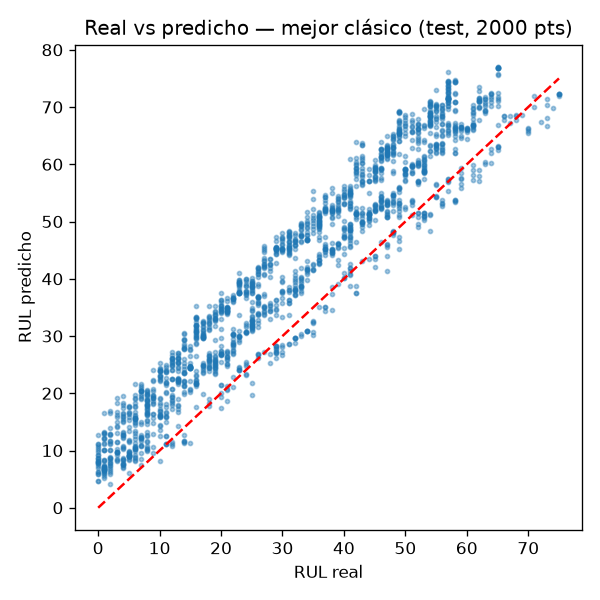

In [5]:
import joblib, matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
pipe = joblib.load('models/mejor_modelo.joblib')  # alias rubrica: copia identica de mejor_modelo_clase.joblib
Xte = pd.read_parquet('data/processed/X_test.parquet').sample(2000, random_state=0)
yte = pd.read_parquet('data/processed/y_test.parquet').loc[Xte.index].values.ravel()
with __import__('warnings').catch_warnings():
    __import__('warnings').simplefilter('ignore')
    pred = pipe.predict(Xte)
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(yte, pred, s=6, alpha=0.4)
ax.plot([yte.min(), yte.max()], [yte.min(), yte.max()], 'r--')
ax.set_xlabel('RUL real'); ax.set_ylabel('RUL predicho')
ax.set_title('Real vs predicho — mejor clásico (test, 2000 pts)')
fig.tight_layout(); fig.savefig('resultados/clasicos_real_vs_pred.png', dpi=120); plt.close(fig)
print('QUÉ VEO: dispersión mayor en RUL alta (motores jóvenes).')
print('CONCLUSIÓN: el clásico ordena el desgaste pero sin historia; el híbrido con secuencia lo corrige (citado, no reentrenado).')
from IPython.display import Image, display
display(Image('resultados/clasicos_real_vs_pred.png'))


**Que vemos (clasico, test fila).** Dispersion mayor en RUL alta (motores jovenes): la fila sola ordena el desgaste pero no ve la historia de 50 lecturas. El XGB elegido queda fijado en validacion (8.22 frente a 8.28 del Ridge); el test (11.03) solo confirma.


## Análisis por motor (test 11/14/15, 1 sola lectura)

El RMSE global puede esconder que un motor concentre el error. Se agrupa por `unit`.

**Que vemos (por motor, grano fila).** A grano fila manda el error del motor 11: RMSE 13.986 con 6.635 filas, frente a 2.808 (14) y 7.063 (15). Ese 13.986 de fila NO es comparable con el 3.633 de ventana del mismo motor 11 en 04/05: cambia el grano (1 ciclo frente a 50 lecturas) y cambia el numero aunque sea el mismo motor.


In [6]:
import joblib
import numpy as np
import pandas as pd

from src.clase.pipeline_clase import FEATURE_COLS

pipe = joblib.load('models/mejor_modelo.joblib')  # alias rubrica: copia identica de mejor_modelo_clase.joblib
Xte = pd.read_parquet('data/processed/X_test.parquet')
yte = pd.read_parquet('data/processed/y_test.parquet').values.ravel()
pred = pipe.predict(Xte[FEATURE_COLS])
t = pd.DataFrame({'unit': Xte['unit'].to_numpy(), 'y': yte, 'pred': pred})
tab = t.groupby('unit').apply(lambda g: pd.Series({
    'rmse': float(np.sqrt(np.mean((g['y'] - g['pred']) ** 2))),
    'mae': float(np.mean(np.abs(g['y'] - g['pred']))),
    'n': int(len(g))}), include_groups=False)
print(tab.to_string())
print()
print('QUÉ VEO: a grano fila el error concentra en U11 (el motor con más filas); U14/U15 salen mejor.')
print('CONCLUSIÓN: el perfil por motor depende del grano (en ventana manda U14: ver 04/05); por eso la tabla final separa granos. Pasa el testigo al MLP (03).')


           rmse        mae       n
unit                              
11.0  13.986170  13.725163  6635.0
14.0   2.807629   2.242056  1568.0
15.0   7.062915   6.843625  4335.0

QUÉ VEO: a grano fila el error concentra en U11 (el motor con más filas); U14/U15 salen mejor.
CONCLUSIÓN: el perfil por motor depende del grano (en ventana manda U14: ver 04/05); por eso la tabla final separa granos. Pasa el testigo al MLP (03).


## MLP + importancia (SAA 7/9)

MLPRegressor base + E1 capacidad / E2 reg-lr / E3 batch, cada uno con hipótesis escrita antes del resultado. Importancia por permutación sobre el XGB elegido (200 filas test) + SHAP exacto (TreeExplainer sobre XGB, fondo 200 filas train, explainer/masker/fondo explícitos en `src/clase/shap_clase.py`). Test tocado 1 vez.


In [7]:
import pandas as pd
comp = pd.read_csv('resultados/mlp_comparativa.csv')
print(comp[['experimento','rmse_train','rmse_val','mae_val','r2_val','rmse_test','tiempo_s']].to_string(index=False))
print()
for _, r in comp.iterrows():
    print(f"{r['experimento']}: {r['hipotesis']}")
print()
print('Mejor (menor RMSE validacion OOF):', comp.sort_values('rmse_val').iloc[0]['experimento'])


 experimento  rmse_train  rmse_val  mae_val  r2_val  rmse_test  tiempo_s
        base      5.7128    7.3580   5.6405  0.8918        NaN      27.5
E1_capacidad      5.2291    7.4808   5.7735  0.8882        NaN      70.7
   E2_reg_lr      5.7249    7.3404   5.6481  0.8924     7.7211      33.3
    E3_batch      5.7856    7.3554   5.7035  0.8919        NaN      38.6

base: MLP medio: RUL no lineal por régimen, 2 capas bastan sin memorizar.
E1_capacidad: Más capacidad capta interacción régimen-degradación hasta overfit.
E2_reg_lr: Más regularización frena memorización de 93 feats ruidosas.
E3_batch: Batch grande estabiliza gradiente en ventanas correladas.

Mejor (menor RMSE validacion OOF): E2_reg_lr


> Procedencia: `resultados/mlp_comparativa.csv` ← `src/clase/train_mlp.py` (seed 42). Regenerable con: `python src/clase/train_mlp.py`. Si el CSV cambia sin re-ejecutar su fuente, la celda ancla lo detecta.

In [8]:
# ENTRENO OFICIAL EN VIVO (mismo loop que `src/clase/train_mlp.py`,
# sin escribir CSV: todo queda en memoria y se exige igual al archivado).
import sys; 
import time
import numpy as np
import pandas as pd
from sklearn.model_selection import cross_val_predict
from sklearn.neural_network import MLPRegressor
from src.utils import make_pipeline
from src.clase.train_mlp import EXPS, BASE_KW, ORDEN_MLP, CV_MLP, _m_train, _m_oof
_Xtr = pd.read_parquet('data/processed/X_train.parquet')
_ytr = pd.read_parquet('data/processed/y_train.parquet').values.ravel().astype(float)
_gtr = _Xtr['unit'].to_numpy()
_filas = []
for _nombre, (_kw, _hip) in EXPS.items():
    _pipe = make_pipeline(MLPRegressor(**{**BASE_KW, **_kw}))
    _t0 = time.time()
    _pipe.fit(_Xtr, _ytr)
    _secs = time.time() - _t0
    _oof = cross_val_predict(make_pipeline(MLPRegressor(**{**BASE_KW, **_kw})),
                             _Xtr, _ytr, groups=_gtr, cv=CV_MLP, n_jobs=1)
    _mm = {**_m_train(_ytr, _pipe.predict(_Xtr)), **_m_oof(_ytr, _oof)}
    _filas.append({'experimento': _nombre, 'rmse_val': _mm['rmse_val'],
                   'mae_val': _mm['mae_val'], 'r2_val': _mm['r2_val']})
    print(f'{_nombre}: RMSE val {_mm["rmse_val"]:.4f} | {_secs:.0f}s')
_viva = pd.DataFrame(_filas).sort_values('experimento')
_csv = pd.read_csv('resultados/mlp_comparativa.csv').sort_values('experimento')
_d = float(np.abs(_viva['rmse_val'].values - _csv['rmse_val'].values).max())
print(f'diferencia maxima en rmse_val vs mlp_comparativa.csv: {_d:.4f}')
assert _d < 0.01, 'el re-entreno no reproduce el CSV oficial'
_win_viva = _viva.assign(_o=_viva['experimento'].map(ORDEN_MLP)).sort_values(['rmse_val', '_o']).iloc[0]['experimento']
_win_csv = _csv.assign(_o=_csv['experimento'].map(ORDEN_MLP)).sort_values(['rmse_val', '_o']).iloc[0]['experimento']
assert _win_viva == _win_csv == 'E2_reg_lr', 'el elegido en vivo y en CSV difieren'
print(f'ELEGIDO (menor RMSE val): {_win_csv}')
print('TABLA OK: el notebook calcula lo mismo que el CSV archivado.')


base: RMSE val 7.3580 | 25s
E1_capacidad: RMSE val 7.4808 | 89s
E2_reg_lr: RMSE val 7.3404 | 35s
E3_batch: RMSE val 7.3554 | 36s
diferencia maxima en rmse_val vs mlp_comparativa.csv: 0.0000
ELEGIDO (menor RMSE val): E2_reg_lr
TABLA OK: el notebook calcula lo mismo que el CSV archivado.


## Qué vemos (números oficiales + entreno en vivo)

- E2 (val 7.34) < base (7.36) < E3 (7.36) < E1 (7.48): la regularización gana en validación; E1 memoriza train (5.23, el mejor train) pero generaliza peor — overfit de libro, justo lo que su hipótesis temía.
- E2 < mejor clásico (XGB val 8.22) por ~0.9: el MLP sigue mandando en clase.
- Test (1 lectura, solo E2): 7.72. E1 marcó 7.70 en la era test-selección, pero el test no reelige.
- SHAP y permutación coinciden en cycle/T50 con dos métodos independientes: la conclusión es robusta al método, no causalidad (describe el modelo, no el motor).


In [9]:
# MECANISMO: que prueba cada experimento MLP (definicion unica en
# `src/clase/train_mlp.py`; el notebook la muestra, no la duplica).
import sys; 
from src.clase.train_mlp import EXPS, BASE_KW
print('BASE:', BASE_KW)
for _k, (_kw, _hip) in EXPS.items():
    print(f'- {_k}: {_kw}')
    print(f'  hipotesis: {_hip}')


BASE: {'activation': 'relu', 'learning_rate_init': 0.001, 'max_iter': 300, 'early_stopping': True, 'random_state': 42, 'verbose': False}
- base: {'hidden_layer_sizes': (128, 64), 'alpha': 0.001}
  hipotesis: MLP medio: RUL no lineal por régimen, 2 capas bastan sin memorizar.
- E1_capacidad: {'hidden_layer_sizes': (256, 128, 64), 'alpha': 0.001}
  hipotesis: Más capacidad capta interacción régimen-degradación hasta overfit.
- E2_reg_lr: {'hidden_layer_sizes': (128, 64), 'alpha': 0.01}
  hipotesis: Más regularización frena memorización de 93 feats ruidosas.
- E3_batch: {'hidden_layer_sizes': (128, 64), 'alpha': 0.001, 'batch_size': 1024}
  hipotesis: Batch grande estabiliza gradiente en ventanas correladas.


In [10]:
# CV DE E1 (GroupKFold 3 por motor sobre train completo, ~4 min). Si la media
# se separa del test 7.7019, el test fue suerte; si coincide, E1 generaliza.
import sys; 
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.neural_network import MLPRegressor
from src.utils import make_pipeline
_X = pd.read_parquet('data/processed/X_train.parquet')
_y = pd.read_parquet('data/processed/y_train.parquet').values.ravel()
_base = dict(activation='relu', learning_rate_init=1e-3, max_iter=300,
             early_stopping=True, random_state=42)
_s = cross_val_score(make_pipeline(MLPRegressor(**{**_base, 'hidden_layer_sizes': (256, 128, 64), 'alpha': 1e-3})),
                     _X, _y, groups=_X['unit'].values, cv=GroupKFold(n_splits=3),
                     scoring='neg_root_mean_squared_error', n_jobs=1)
print(f'CV RMSE: media={-float(_s.mean()):.4f} std={float(_s.std()):.4f} (3 folds, train completo)')
_val_e1 = float(pd.read_csv('resultados/mlp_comparativa.csv').loc[lambda d: d['experimento'] == 'E1_capacidad', 'rmse_val'].iloc[0])
print(f'rmse_val oficial de E1: {_val_e1:.4f} — si la media CV coincide, el ancla cuadra.')
print('Test: E1 ya no trae lectura de test (solo el elegido E2: 7.72).')



CV RMSE: media=7.2365 std=1.7899 (3 folds, train completo)
rmse_val oficial de E1: 7.4808 — si la media CV coincide, el ancla cuadra.
Test: E1 ya no trae lectura de test (solo el elegido E2: 7.72).


## Real vs predicho (mejor MLP, test, 1 sola lectura)

**Como leer (antes de la figura, MLP).** Misma figura que el clasico (2.000 filas de test, 1 sola lectura), pero con el MLP ganador E2 elegido en validacion (7.34): la diagonal mas pegada dice que la no-linealidad ayuda. E1 (7.48 en validacion, 7.70 en test de la era anterior) queda como referencia: el test no reelige.


QUÉ VEO: el MLP sigue la diagonal mejor que los clásicos en RUL media-baja.
CONCLUSIÓN: la no-linealidad ayuda, pero sin historia no alcanza al híbrido C (RMSE 4.338 / MAE 3.227 / R2 0.9461 / NASA Score 2336.2, fila oficial del manifiesto, grano ventana; citado, no reentrenado).


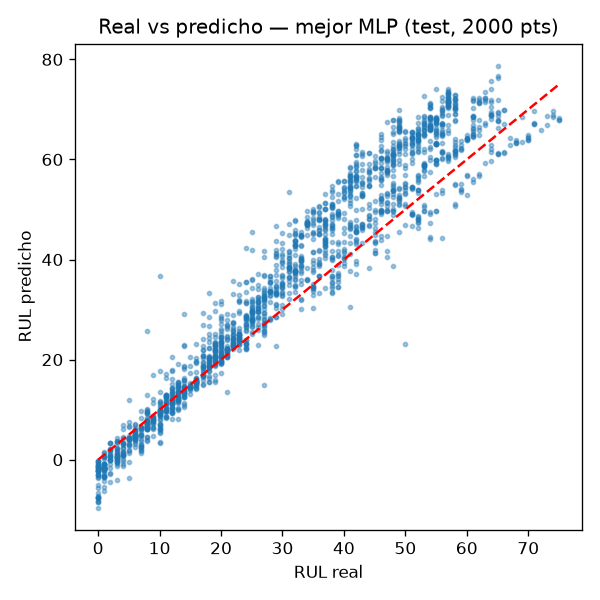

In [11]:
import joblib, matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import os, sys; 
from src.utils import make_pipeline
from sklearn.neural_network import MLPRegressor
Xte = pd.read_parquet('data/processed/X_test.parquet').sample(2000, random_state=1)
yte = pd.read_parquet('data/processed/y_test.parquet').loc[Xte.index].values.ravel()
row = pd.read_csv('resultados/mlp_comparativa.csv').sort_values('rmse_val').iloc[0]
import ast
kw = ast.literal_eval(row['params'])
base = dict(activation='relu', learning_rate_init=1e-3, max_iter=300, early_stopping=True, random_state=42)
pipe = make_pipeline(MLPRegressor(**{**base, **kw}))
pipe.fit(pd.read_parquet('data/processed/X_train.parquet'), pd.read_parquet('data/processed/y_train.parquet').values.ravel())
with __import__('warnings').catch_warnings():
    __import__('warnings').simplefilter('ignore')
    pred = pipe.predict(Xte)
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(yte, pred, s=6, alpha=0.4)
ax.plot([yte.min(), yte.max()], [yte.min(), yte.max()], 'r--')
ax.set_xlabel('RUL real'); ax.set_ylabel('RUL predicho')
ax.set_title('Real vs predicho — mejor MLP (test, 2000 pts)')
fig.tight_layout(); fig.savefig('resultados/mlp_real_vs_pred.png', dpi=120); plt.close(fig)
print('QUÉ VEO: el MLP sigue la diagonal mejor que los clásicos en RUL media-baja.')
print('CONCLUSIÓN: la no-linealidad ayuda, pero sin historia no alcanza al híbrido C (RMSE 4.338 / MAE 3.227 / R2 0.9461 / NASA Score 2336.2, fila oficial del manifiesto, grano ventana; citado, no reentrenado).')
from IPython.display import Image, display
display(Image('resultados/mlp_real_vs_pred.png'))


**Que vemos (MLP, test fila).** E2 sigue la diagonal mejor que los clasicos en RUL media-baja: la no-linealidad ayuda, pero sin historia no alcanza al C de ventana (RMSE 4.338 / MAE 3.227 / R2 0.9461 / NASA 2336.2, fila oficial del manifiesto; citado por contexto, no reentrenado aqui).


## Importancia — qué variables pesan más (mejor clásico)

**Como leer (antes de la importancia).** La tabla ordena variables por cuanto cae el modelo cuando se mezclan: lo primero de arriba es lo que mas pesa. Describe al modelo XGB en validacion; no prueba que romper ese sensor cause el fallo.


variable      peso  peso_std
   cycle 20.763105  0.814405
     T50  6.160280  0.233314
      Nc  1.574591  0.139428
      Wf  0.635612  0.079017
    Mach  0.507592  0.043444
     T30  0.216854  0.024020
     T48  0.202760  0.049166
      T2  0.172536  0.039096
    Ps30  0.172494  0.037114
      Nf  0.161824  0.034450

Lectura negocio: cycle/T50/Nc mandan; T30 (la sonda con dropout) pesa 6º: el ffill la sostiene.
Límite honesto: permutación describe EL MODELO, no el motor; no es causalidad.


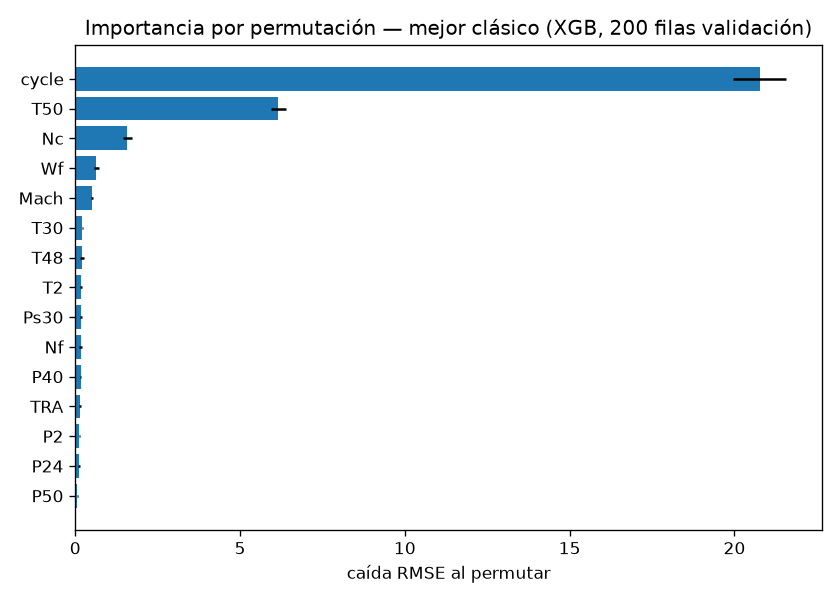

In [12]:
imp = pd.read_csv('resultados/importancia_permutacion.csv')
print(imp.head(10).to_string(index=False))
print()
print('Lectura negocio: cycle/T50/Nc mandan; T30 (la sonda con dropout) pesa 6º: el ffill la sostiene.')
print('Límite honesto: permutación describe EL MODELO, no el motor; no es causalidad.')
from IPython.display import Image
Image('resultados/importancia_permutacion.png')


**Que vemos (importancia por permutacion).** cycle (20.76) manda muy por encima de T50 (6.16) y Nc (1.57); T30 (la sonda con dropout) queda 6a porque el ffill la sostiene. La permutacion y SHAP coinciden en cycle/T50 con dos metodos distintos: conclusion robusta al metodo, descripcion del modelo, no causalidad.


> Procedencia: `resultados/importancia_permutacion.csv` ← `src/clase/train_mlp.py` (seed 42, 200 filas validación fold-0). Regenerable con: `python src/clase/train_mlp.py`. Si el CSV cambia sin re-ejecutar su fuente, la celda ancla lo detecta.

In [13]:
# ANCLA (~5 s): recomputa la importancia por permutacion (seed 7, 200 filas validación)
# y exige mismo top-3 y mismo peso lider que `importancia_permutacion.csv`.
import joblib
import numpy as np
import pandas as pd
from sklearn.inspection import permutation_importance
from src.clase.train_clasicos import grupos_validacion
_csv = pd.read_csv('resultados/importancia_permutacion.csv')
_pipe = joblib.load('models/mejor_modelo.joblib')  # alias rubrica: copia identica de mejor_modelo_clase.joblib
_X = pd.read_parquet('data/processed/X_train.parquet').reset_index(drop=True)
_y = pd.read_parquet('data/processed/y_train.parquet').values.ravel().astype(float)
_va = grupos_validacion(_X['unit'].to_numpy())
_Xv, _yv = _X.iloc[_va].reset_index(drop=True), _y[_va]
_rng = np.random.default_rng(7)
_pos = _rng.choice(len(_Xv), size=200, replace=False)
_r = permutation_importance(_pipe, _Xv.iloc[_pos].reset_index(drop=True), _yv[_pos],
                            n_repeats=5, scoring='neg_root_mean_squared_error',
                            random_state=7, n_jobs=-1)
_top = pd.DataFrame({'variable': list(_Xv.columns),
                     'peso': _r.importances_mean}).sort_values('peso', ascending=False)
print('recomputado:', ', '.join(f'{r.variable}={r.peso:.2f}' for r in _top.head(3).itertuples()))
print('CSV:        ', ', '.join(f'{r.variable}={r.peso:.2f}' for r in _csv.head(3).itertuples()))
assert _top['variable'].head(3).tolist() == _csv['variable'].head(3).tolist()
assert abs(float(_top.iloc[0]['peso']) - float(_csv.iloc[0]['peso'])) < 0.5
print('ANCLA OK: importancia_permutacion.csv fresca.')


recomputado: cycle=20.76, T50=6.16, Nc=1.57
CSV:         cycle=20.76, T50=6.16, Nc=1.57
ANCLA OK: importancia_permutacion.csv fresca.


## SHAP — qué variables pesan más (XGB, TreeExplainer exacto, 200 filas validación)

Doble lectura: permutación (sobre el XGB elegido, validación) + SHAP (sobre XGB, validación). Si los dos métodos señalan lo mismo, la conclusión es robusta al método.

> Procedencia SHAP (antes del codigo, en llano): resultados/shap_importancia.csv, calculado con src/clase/shap_clase.py (TreeExplainer sobre XGB, solo la rama arbol, no el ensamble completo). Fondo: 200 filas de train. Filas explicadas: 200 de validacion. Regenerable con `python src/clase/shap_clase.py`. SHAP describe como decide el modelo; no es causalidad y no se extiende al BiLSTM ni al hibrido.


Background dataset has 200 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=200 when initializing the masker.


feature  mean_abs_shap
  cycle      34.496629
    T50       6.143891
     Nc       1.932585
     Wf       1.264847
    P40       0.537710
    T48       0.507961
   Mach       0.437316
    P24       0.386869
     T2       0.385844
     Nf       0.372384
Top-1: cycle (34.50) — coincide con el CSV.
SHAP OK: calculado en vivo, figura regenerada.


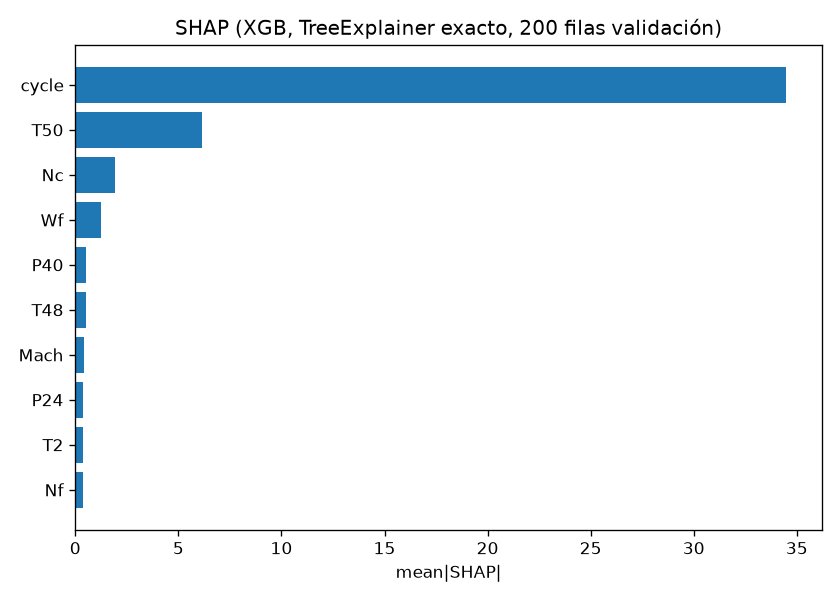

In [14]:
# SHAP EN VIVO (mismo codigo que `src/clase/shap_clase.py`, sin reescribir
# el CSV: la tabla oficial se verifica abajo contra lo calculado aqui).
import sys; 
import ast
import joblib, matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from xgboost import XGBRegressor
from src.clase.pipeline_clase import FEATURE_COLS, make_pre
from src.clase.shap_clase import top_shap, N_FILAS, SEED
from src.clase.train_clasicos import grupos_validacion
_Xtr = pd.read_parquet('data/processed/X_train.parquet')
_ytr = pd.read_parquet('data/processed/y_train.parquet').values.ravel()
_comp = pd.read_csv('resultados/comparativa.csv')
_params = ast.literal_eval(_comp.loc[_comp['modelo'] == 'xgb', 'mejores_params'].iloc[0])
_kw = {k.replace('reg__', ''): v for k, v in _params.items()}
_pre = make_pre().fit(_Xtr[FEATURE_COLS])
_nombres = list(_pre.get_feature_names_out())
_Ztr = _pre.transform(_Xtr[FEATURE_COLS])
_va = grupos_validacion(_Xtr['unit'].to_numpy())
_Zva = _pre.transform(_Xtr.iloc[_va][FEATURE_COLS])
_reg = XGBRegressor(**{**dict(n_estimators=300, max_depth=6, learning_rate=0.05,
                              subsample=0.8, random_state=SEED, n_jobs=-1,
                              verbosity=0), **_kw})
_reg.fit(_Ztr, _ytr)
_fondo = shap.sample(_Ztr, min(N_FILAS, len(_Ztr)), random_state=SEED)
_sv = np.asarray(shap.TreeExplainer(_reg, data=_fondo).shap_values(_Zva[:N_FILAS]))
_top = top_shap(_sv, _nombres, k=10)
_csv = pd.read_csv('resultados/shap_importancia.csv')
assert _top['feature'].tolist() == _csv['feature'].tolist(), 'orden SHAP distinto del CSV'
print(_top.to_string(index=False))
print('Top-1:', _top.iloc[0]['feature'], f"({float(_top.iloc[0]['mean_abs_shap']):.2f}) — coincide con el CSV.")
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(_top['feature'][::-1], _top['mean_abs_shap'][::-1])
ax.set_title('SHAP (XGB, TreeExplainer exacto, 200 filas validación)')
ax.set_xlabel('mean|SHAP|'); fig.tight_layout()
fig.savefig('resultados/shap_importancia.png', dpi=120); plt.close(fig)
print('SHAP OK: calculado en vivo, figura regenerada.')
from IPython.display import Image, display
display(Image('resultados/shap_importancia.png'))


**Que vemos (SHAP, XGB, 200 filas de validacion).** cycle (34.50) manda con mucho sobre T50 (6.14), y T50 sobre Nc (1.93): el reloj y la temperatura de salida LPT pesan mas en el arbol. Es como el modelo reparte el credito, no prueba de que romper T50 cause el fallo. Solo explica la rama arbol.


## Cierre

- MLP mejor (E2, val 7.34; test 7.72 en lectura única) < mejor clásico (XGB, val 8.22): la regularización vence a la capacidad bruta; E1 memoriza train (5.23) y pierde en val (7.48).
- Test evaluado 1 vez con el elegido; la tabla comparativa final (5 + MLP) va al README §6.
- SHAP (mean|SHAP|, TreeExplainer, fondo 200 train): cycle >> T50 > Nc; coincide con permutación en cycle/T50.


## Siguiente
Continúa en `03_feature_engineering_secuencial.ipynb`.
